In [4]:
import astropy as ast #for constants etc
import astropy.constants as cst #constants 
import numpy as np
import matplotlib.pyplot as plt
import scipy as sci

# Following similar procedure as to in 'Neutron stars for undergraduates'
# Richard R. Silbar; Sanjay Reddy (2004)
# https://doi.org/10.1119/1.1703544
# the ratio of Z/A = 2 

##################################################################

c = cst.c.value # speed of light 
atomic_ratio = 2 
m_N = (cst.m_n.value + cst.m_p.value)/2
gamma = 5/3
R_0 = (cst.G.value * cst.M_sun.value) / (c**2)
eps_0 = 0.013



def K_nr(eps_0):
    return (cst.hbar.value**2) / (15 *np.pi**2 * cst.m_e.value) * ((3 * np.pi * (1/atomic_ratio) / (m_N * c**2))**(5/3))

def beta_nr(eps_0):
    return (4 * np.pi * eps_0)/(cst.M_sun.value * c**2 * (K_nr(eps_0) * eps_0**(gamma - 1)**(1/gamma)))

def alpha_nr(eps_0):
    return R_0 / ((K_nr(eps_0) * eps_0**(1/gamma))**(1 - gamma))


def dH_dr(t, eqns, Gamma, Alpha, Beta, eps_0):
    Arr = [(-Alpha(eps_0) * eqns[1]** (1/Gamma) * eqns[0]) / t**2 , 
            Beta(eps_0) * t**2 * (eqns[1])**(1/Gamma)]
    return np.array(Arr)

##################################################################



# 8900km WD 1Sol mass

# A2 poster
# Non specialised audinece 



# there's enough there toa ask about if you're stood there

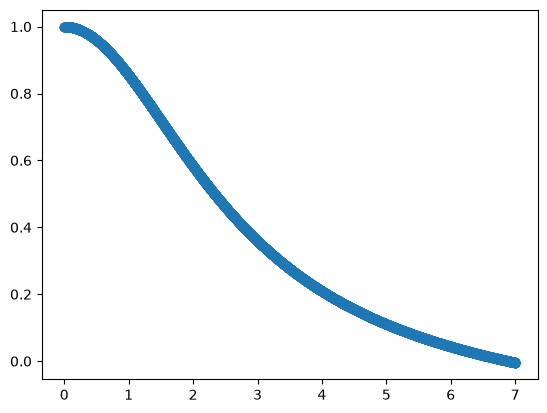

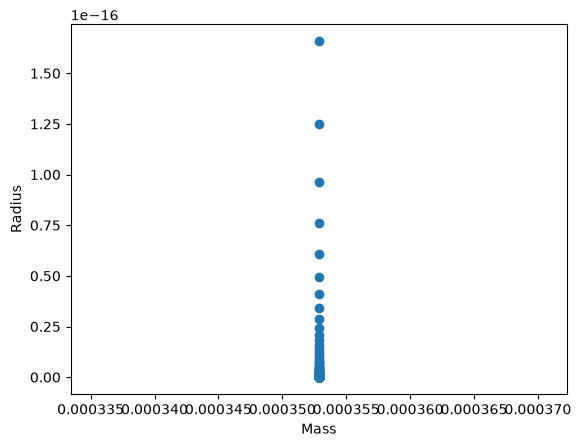

In [82]:
import astropy as ast #for constants etc
import astropy.constants as cst #constants 
import numpy as np
import matplotlib.pyplot as plt
import scipy as sci
import numba
import math

# Following similar procedure as to in 'Neutron stars for undergraduates'
# Richard R. Silbar; Sanjay Reddy (2004)
# https://doi.org/10.1119/1.1703544
# the ratio of Z/A = 2 

## Runga-kutta explicit method 
# fns = [u(theta(xi)), theta(xi)]

# Note: AI (Claude Sonnet 5.5) on low setting was used to assist in debugging the Runga-Kutta 4(5) 
#      and in the linear extrapolation.


c = cst.c.value # speed of light 
atomic_ratio = 2 #A/Z
m_N = (cst.m_n.value + cst.m_p.value)/2
gamma = 4/3
R_0 = (cst.G.value * cst.M_sun.value) / (c**2)
eps_0 = np.linspace(100000, 10000000, 1000)
solar_mass = cst.M_sun.value
solar_radius = cst.R_sun.value


# for n = 3 use 7000, 0.001
# for n = 3/2 use 4000, 0.001
steps = 7000
infintesimal = 0.001
order_n = 1
initial_radius = 0.000000000001 
ns = [3]

K_rel = (cst.hbar.value * c) / (12 * math.pi **2 ) * ((3 * math.pi ** 2) / (2 * m_N * c **2)) ** (gamma)


X = np.array([0., 1.]) # these are initial conditions 

def Lane_Emden(t, fns, n): # this takes inputs [theta' = >>>>>u /xi^2<<<<<< , >>>>-theta^n * xi^2<<<<< = u']
    coupling = np.array([- (fns[1] ** n) * t**2, fns[0]/(t**2)])
    return coupling 


def RK4(f, initial_conditions, initial_radius, dxi, n_steps, n):
    con = np.zeros((n_steps + 1, 2))
    con[0] = initial_conditions # the initial conditions (must be an array)

    for i in range (0, n_steps):
        k_1 = f(initial_radius + i*dxi, con[i],  n )
        N_2 = con[i] + (k_1*dxi/2)
        k_2 = f((initial_radius + i*dxi+dxi/2), N_2, n )
        N_3 = con[i] + (k_2*dxi/2)
        k_3 = f( initial_radius + i*dxi+dxi/2, N_3,  n )
        N_4 = con[i] + (k_3*dxi)
        k_4 = f(initial_radius + i*dxi+dxi, N_4,  n )
        k = 1/6 * (k_1 + 2*k_2 + 2*k_3 + k_4)
        con[i+1] = (con[i] + dxi * k)
    return con # this integrates ( in general [f(xi), g(xi)] ), but in our case integrates [u /xi^2 = theta', -theta^n * xi^2 = u'] 


def linear_line(grad, intercept, x):
    return grad * x + intercept

def zero_finder(xs, ys, dxi): # this uses a linear interpolation (assuming a single monotone decreacing function)
    positive_values = np.where(ys > 0) # array of the position all y values greater than 0
    # j = 0
    # while positive_values[0][j] + 1 == positive_values[0][j]: # Checks for if the function is not monotone decreacing, then returns the first position to interpolate
    #     j += 1
    #     print(j)
    #     if j > 120000:
    #         print("Could not find last positive x value position, loop too long")
    #         break
    #     last_positive = j
    #     return last_positive   
    last_positive = np.array(positive_values)[0][-1] # the >>position<< of the last positive y value
    dy = ys[last_positive-1] - ys[last_positive-2]
    dx = xs[last_positive-1] - xs[last_positive-2]
    last_positive_x = xs[last_positive]
    gradient = dy/dx
    intercept = (-1 *gradient* last_positive_x) + ys[last_positive]
    scale_down = 100
    step_size_interpolation = dxi / scale_down
    k = 0
    interpolation = np.zeros(1000000)
    interpolation[0] = ys[last_positive]
    while interpolation[k] > 0:
        interpolation[k + 1] = linear_line(gradient, intercept, last_positive_x + (step_size_interpolation * k) )
        k += 1
        
        if k > (200* scale_down):
            print('While loop ran for too long')
            break
    zero_middle_position_x = ((last_positive_x + step_size_interpolation * (k + 1)) + (last_positive_x + step_size_interpolation * k)) / 2
    # [postion in x where the function is 0, the position in the array where x is last positive, the dx to reach the interpolated 0 of the function]         
    return [zero_middle_position_x, int(last_positive), k * step_size_interpolation]



def linear_extrapolator(xs, ys, dx_to_0, last_known_x_position, last_known_x):
    last_x = last_known_x_position
    dy = ys[last_x-1] - ys[last_x-2]
    dx = xs[last_x-1] - xs[last_x-2]
    last_positive_x = xs[last_x]
    gradient = dy/dx
    intercept = (-1 *gradient* last_positive_x) + ys[last_x]
    return linear_line(gradient, intercept, (last_known_x + dx_to_0))





plt.figure()


for k in range(len(ns)):
    solved = RK4(Lane_Emden, X, initial_radius, infintesimal, steps, n = ns[k])
    plt.scatter(initial_radius + infintesimal * np.arange(steps + 1), solved[:,1])

ax = plt.gca()

plt.show()



# # test_xs = np.array([1,2,3,4,5])
# # test_ys = np.array([3,1,-1,-3,-5])

# print(zero_finder(test_xs, test_ys, infintesimal))
        
# ################################################################################################################################################################
# # Finding the mass radius relation 
# ################################################################################################################################################################

n = ns[0]

xi_values = initial_radius + infintesimal * np.arange(steps + 1)

zero_finder_dict = zero_finder(xi_values, solved[:,1], infintesimal)



xi_1 = zero_finder_dict[0]

# ################################################################################################################################################################
# # MUST CHANGE
# ################################################################################################################################################################

# [postion in x where the function is 0, the position in the array where x is last positive, the dx to reach the interpolated 0 of the function]
# (xs, ys, dx_to_0, last_known_x_position, last_known_x)

theta_prime_1_inter = abs(linear_extrapolator(xi_values, solved[:,0], zero_finder_dict[2], zero_finder_dict[1],  zero_finder_dict[0])) #DO NOT LEAVE THIS HERE
# ################################################################################################################################################################
# # End MUST CHANGE
# ################################################################################################################################################################


# print("For value of n = " +str(n) + " $\ix$ is : " +str(xi_1))
# print("theta prime * xi^2 = " +str(theta_prime_1_inter))

K_nr = (cst.hbar.value**2) / (15 *math.pi**2 * cst.m_e.value) * ((3 * math.pi * (1/atomic_ratio) / (m_N * c**2))**(5/3))





MASS = []
RADIUS = []

# for i in range(len(eps_0)):
#     Mass_constants = (4 * math.pi * (((n + 1) * K_nr)/ (4 * math.pi * cst.G.value))**(3/2) * (eps_0[i])**((3-n)/2*n))
#     Radius_constants = (((n + 1) * K_nr)/ (4 * math.pi * cst.G.value))**(1/2) 
#     MASS.append((Mass_constants * (eps_0[i] ** ((3-n)/2) * (theta_prime_1_inter))) * solar_mass)

#     RADIUS.append((Radius_constants * eps_0[i] ** ((1-n)/2*n) * xi_1) * solar_radius)



for i in range(len(eps_0)):
    Mass_constants = (4 * math.pi * (((n + 1) * K_rel)/ (4 * math.pi * cst.G.value))**(3/2) * (eps_0[i])**((3-n)/2*n))
    Radius_constants = (((gamma * K_rel)/ ((gamma - 1)*4 * math.pi * cst.G.value)))**(1/2) 
    
    MASS.append((Mass_constants * (eps_0[i] ** ((2 * (gamma - 4/3))/3) * (theta_prime_1_inter))) )
    RADIUS.append((Radius_constants * eps_0[i] ** ((1-n)/2*n) * xi_1) )


plt.ylabel('Radius')
plt.xlabel('Mass')
plt.scatter(MASS,RADIUS)
plt.show()


# MASS = Mass_constants * (eps_0 ** ((3-n)/2) * (theta_prime_1_inter))
# RADIUS = Radius_constants * eps_0 ** ((1-n)/2*n) * xi_1



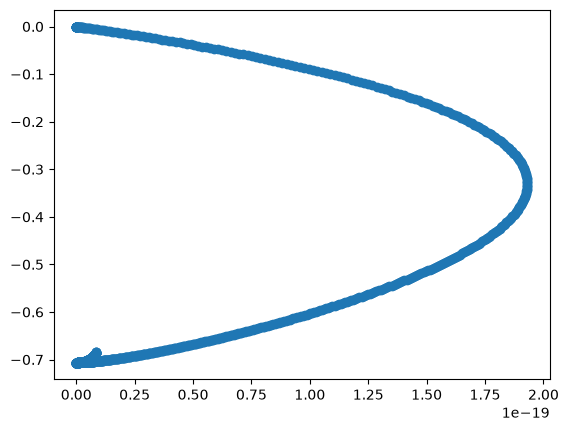

In [65]:
#######################################################
            # >>>> Using solve_ivp <<<< #
#######################################################
import astropy as ast #for constants etc
import astropy.constants as cst #constants 
import numpy as np
import matplotlib.pyplot as plt
import scipy as sci
import math

X = np.array([0., 1.]) # these are initial conditions 


ns = 3
def Lane_Emden(t, fns, n):
    coupling = np.array([- (fns[1] ** n) * t**2, fns[0]/(t**2)])
    return coupling

solved = sci.integrate.solve_ivp(Lane_Emden, [0.000000000000000000001, 10], X, args = (ns,), max_step = 0.01)


# plt.scatter(solved.t, solved.y[1])

n = ns
eps_0 = 0.01

K_nr = (cst.hbar.value**2) / (15 *math.pi**2 * cst.m_e.value) * ((3 * math.pi * (1/atomic_ratio) / (m_N * c**2))**(5/3))



Mass_constants = 4 * math.pi * (((n + 1) * K_nr)/ (4 * math.pi * cst.G.value))**(3/2) * (eps_0 * cst.c.value ** 2 )**((3-n)/2*n)

MASS = Mass_constants * (eps_0 ** ((3-n)/2) * (solved.y[1] **2) * abs(solved.y[0]))

Radius_constants = (((n + 1) * K_nr)/ (4 * math.pi * cst.G.value))**(1/2) 
RADIUS = Radius_constants * eps_0 ** ((1-n)/2*n) * solved.y[0]

plt.scatter(MASS,RADIUS)

In [59]:
%pip install numba

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 40.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.7/59.7 MB 58.5 MB/s  0:00:01 eta 0:00:010:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [numba]━━━━━ 1/2 [numba]

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: /home/thomas/.local/share/pipx/venvs/notebook/bin/python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [93]:
###################
# Solve IVP and mass-pressure intigration
###################

import astropy as ast #for constants etc
import astropy.constants as cst #constants 
import numpy as np
import matplotlib.pyplot as plt
import scipy as sci
import math


##################
# constants 
##################

c = cst.c.value # speed of light 
atomic_ratio = 2 #A/Z
m_N = (cst.m_n.value + cst.m_p.value)/2
gamma = 4/3
R_0 = (cst.G.value * cst.M_sun.value) / (c**2)
eps_0 = np.linspace(100000, 10000000, 1000)
solar_mass = cst.M_sun.value
solar_radius = cst.R_sun.value

X = np.array([0, 1]) # the initial conditions

##################
# functions 
##################

def gamma(is_rel):
    """non-relativistic, relativistic"""
    arr = [5/3, 4/3]
    out = arr[is_rel]
    return out

def K(is_rel):
    """Call K[0] for non-relativistic, K[1] for relativistic (note this is a constant)"""
    rel = (cst.hbar.value * c) / (12 * math.pi **2 ) * ((3 * math.pi ** 2 * (1 / atomic_ratio)) / ( m_N * c **2)) ** (gamma(is_rel))
    non_rel = (cst.hbar.value**2) / (15 *math.pi**2 * cst.m_e.value) * (((3 * math.pi**2 * (1/atomic_ratio)) / ((m_N * c**2)))**(gamma(is_rel)))
    if is_rel == 1:
        return rel
    if is_rel == 0:
        return non_rel

def beta(eps_0, is_rel):
    """ (value for epsilon 0 (can be array), 1 = relativistic 0 = non relativistic)"""
    return (4 * np.pi * eps_0)/(cst.M_sun.value * c**2 * (K(is_rel) * eps_0**(gamma(is_rel) - 1)**(1/gamma(is_rel))))

def alpha(eps_0, is_rel):
    """ value for epsilon 0 (can be array), 1 = relativistic 0 = non relativistic"""
    return R_0 / ((K(is_rel) * eps_0**(1/gamma(is_rel)))**(1 - gamma(is_rel)))


def dH_dr(t, fns, Alpha, Beta, eps_0, is_rel):
    Arr = [(-Alpha(eps_0, is_rel) * fns[1]** (1/gamma(is_rel)) * fns[0]) / t**2 , 
            Beta(eps_0, is_rel) * t**2 * (fns[1])**(1/gamma(is_rel))]
    return np.array(Arr)

##################
# accessing saved data
##################


##################
# solving coupled equations
##################

# solved = sci.integrate.solve_ivp(dH_dr, 


##################
# central pressure solving
##################


##################
# plotting 
##################


##################
# saving values 
##################




1.2128841874431485e-13
